<a href="https://www.kaggle.com/code/aamir28/student-ai-usage-grades-dependency?scriptVersionId=361691232" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

<div style="background:linear-gradient(135deg,#080c2b 0%,#16124d 55%,#2b2a8f 100%);padding:42px 44px;border-radius:20px;color:#f4f7ff;box-shadow:0 8px 28px rgba(8,12,43,.35);font-family:'Segoe UI',Arial,sans-serif"><div style="letter-spacing:3px;font-size:13px;color:#48d6e6;font-weight:bold">EDA &amp; MODELLING NOTEBOOK &nbsp;&middot;&nbsp; 1,200 STUDENTS &nbsp;&middot;&nbsp; 12 COUNTRIES</div><div style="font-size:50px;font-weight:bold;line-height:1.08;margin:12px 0 8px 0">Student AI Usage, Grades <span style="color:#48d6e6">&amp; Dependency</span> &#127891;</div><div style="font-size:19px;color:#cdd6f8;max-width:820px;line-height:1.5">How do students use ChatGPT, Gemini and Claude, and what does it do to their grades, critical thinking and academic integrity?</div><div style="margin-top:20px;display:flex;gap:10px;flex-wrap:wrap;font-size:13px"><span style="background:rgba(72,214,230,.16);border:1px solid #48d6e6;color:#9ff0fa;padding:5px 12px;border-radius:20px">pandas</span><span style="background:rgba(139,108,255,.18);border:1px solid #8b6cff;color:#cbbfff;padding:5px 12px;border-radius:20px">matplotlib</span><span style="background:rgba(255,196,70,.15);border:1px solid #ffc446;color:#ffe0a0;padding:5px 12px;border-radius:20px">scikit-learn</span><span style="background:rgba(255,255,255,.08);border:1px solid #6b74b8;color:#b9c2ee;padding:5px 12px;border-radius:20px">Synthetic dataset for learning</span></div></div>

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">1</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">Setup &amp; load the data</div><div style="font-size:14px;color:#5b6498;margin-top:3px">Imports, a custom colour theme and a first look at the table</div></div></div>

In [1]:
import glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore")

# ---- Theme: navy / cyan / violet ----
INK, CYAN, VIOLET, CORAL, GOLD, MINT = "#141a46", "#17b8cf", "#7b5cff", "#ff6b6b", "#ffb703", "#2dd4a8"
BG, GRID, MUTED = "#f7f9ff", "#e1e7fb", "#6a72a8"
mpl.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

path = (glob.glob("/kaggle/input/datasets/aamir28/student-ai-usage-and-academic-performance-2026/campus_ai_pulse_2026.csv", recursive=True) + glob.glob("*ai_pulse_2026.csv"))[0]
df = pd.read_csv(path)
print(f"{df.shape[0]:,} students x {df.shape[1]} columns | missing values: {df.isna().sum().sum()} | duplicate rows: {df.duplicated().sum()}")

# helper bins used throughout
labels = ["Non-users", "0-5 h", "5-10 h", "10-15 h", "15-20 h", "20+ h"]
df["ai_hours_bin"] = pd.cut(df["ai_hours_per_week"], [-1, 0, 5, 10, 15, 20, 100], labels=labels)
users = df[df["uses_ai"] == "Yes"]

df.drop(columns="ai_hours_bin").head()

1,200 students x 24 columns | missing values: 0 | duplicate rows: 0


,student_id,age,gender,country,university_type,program,year_of_study,uni_ai_policy,uses_ai,primary_ai_tool,...,ai_assignment_share_pct,study_hours_per_week,cgpa,critical_thinking_score,time_saved_pct,ai_dependency_score,ai_dependency_level,integrity_concern_level,flagged_by_ai_detector,would_recommend_ai
0,S0001,20,Female,India,Public,Engineering,2,Allowed,Yes,ChatGPT,...,51,13.7,2.88,53,47,8,High,3,Yes,No
1,S0002,22,Male,Nigeria,Private,Computer Science,2,No clear policy,Yes,ChatGPT,...,11,19.8,3.52,84,29,2,Low,3,No,Yes
2,S0003,21,Male,United States,Private,Business,4,Allowed with disclosure,Yes,Perplexity,...,11,20.4,2.94,72,20,2,Low,3,No,Yes
3,S0004,22,Female,Bangladesh,Private,Medicine & Health,3,No clear policy,Yes,Claude,...,46,18.0,2.70,68,23,6,Medium,1,No,Yes
4,S0005,20,Male,Bangladesh,Private,Natural Sciences,1,Allowed,Yes,ChatGPT,...,9,24.8,3.01,62,19,3,Low,1,No,No


<div style="margin:18px 0 6px 0;font-size:13px;letter-spacing:2px;color:#6a72a8;font-weight:bold;font-family:'Segoe UI',Arial,sans-serif">DATASET AT A GLANCE</div><div style="display:flex;gap:14px;flex-wrap:wrap;margin:10px 0"><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #17b8cf;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">Students</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">1,200</div><div style="font-size:13px;color:#6a72a8">12 countries, 7 programs</div></div><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #17b8cf;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">AI adoption</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">88%</div><div style="font-size:13px;color:#6a72a8">1,052 students use AI tools</div></div><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #17b8cf;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">Avg AI time</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">6.7 h</div><div style="font-size:13px;color:#6a72a8">per week, among users</div></div><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #17b8cf;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">Avg CGPA</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">3.04</div><div style="font-size:13px;color:#6a72a8">on a 4.0 scale</div></div><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #17b8cf;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">Data quality</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">0 missing</div><div style="font-size:13px;color:#6a72a8">no duplicate rows, ready to analyse</div></div></div>

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">2</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">Who uses AI, and which tools?</div><div style="font-size:14px;color:#5b6498;margin-top:3px">Tool market share among users, and weekly AI hours by field of study</div></div></div>

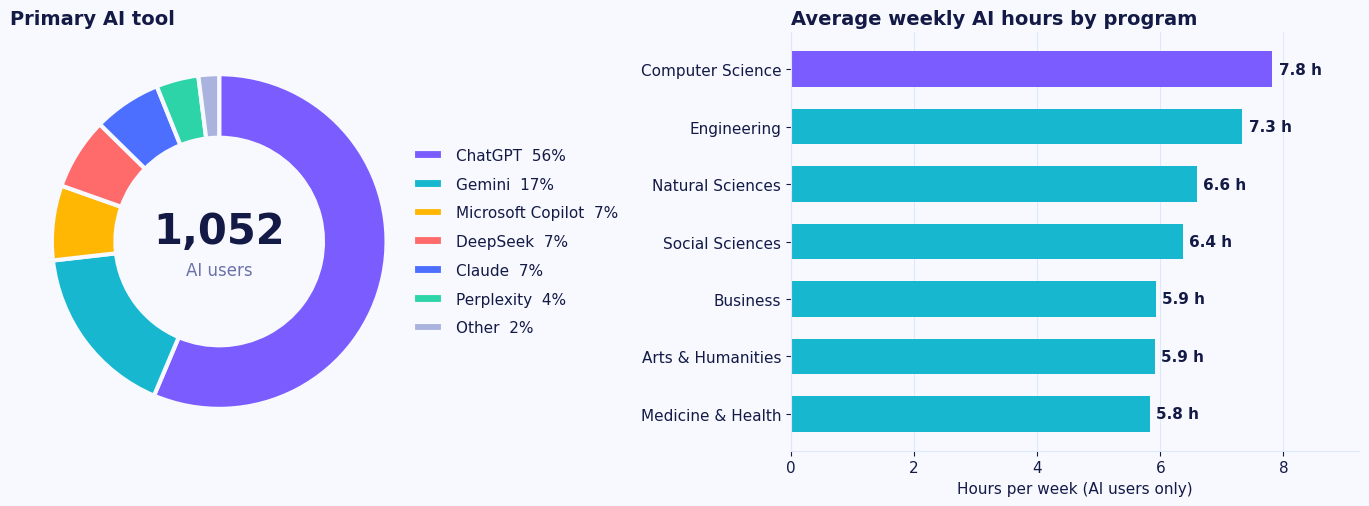

In [2]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})

tool = users["primary_ai_tool"].value_counts()
cols = [VIOLET, CYAN, GOLD, CORAL, "#4c6fff", MINT, "#aab3dd"]
wedges, _ = a.pie(tool.values, colors=cols[:len(tool)], startangle=90, counterclock=False,
                  wedgeprops=dict(width=.38, edgecolor=BG, linewidth=3))
a.text(0, .06, f"{len(users):,}", ha="center", va="center", fontsize=30, fontweight="bold")
a.text(0, -.17, "AI users", ha="center", va="center", fontsize=12, color=MUTED)
a.legend(wedges, [f"{t}  {v/tool.sum()*100:.0f}%" for t, v in tool.items()], loc="center left",
         bbox_to_anchor=(.93, .5), fontsize=11, labelspacing=.9)
a.set_title("Primary AI tool"); a.grid(False)

h = users.groupby("program")["ai_hours_per_week"].mean().sort_values()
colors = [VIOLET if v == h.max() else CYAN for v in h.values]
bars = b.barh(h.index, h.values, color=colors, height=.62)
for r, v in zip(bars, h.values):
    b.text(v + .1, r.get_y() + r.get_height()/2, f"{v:.1f} h", va="center", fontweight="bold")
b.set_xlim(0, h.max()*1.18); b.grid(axis="y", visible=False)
b.set_title("Average weekly AI hours by program"); b.set_xlabel("Hours per week (AI users only)")
plt.tight_layout(); plt.show()

<div style="background:#effbfd;border-left:5px solid #17b8cf;border-radius:10px;padding:14px 18px;color:#141a46;font-size:15px;line-height:1.6;margin:6px 0 4px 0;font-family:'Segoe UI',Arial,sans-serif"><b style="color:#0a8aa0">&#128161; Insight:</b> <b>ChatGPT</b> leads with 56% of users, followed by Gemini (17%). <b>Computer Science</b> students spend the most time with AI (7.8 h a week), about 1.3x the Medicine & Health average (5.8 h).</div>

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">3</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">What do students actually use AI for?</div><div style="font-size:14px;color:#5b6498;margin-top:3px">Share of each program&rsquo;s users by main use case</div></div></div>

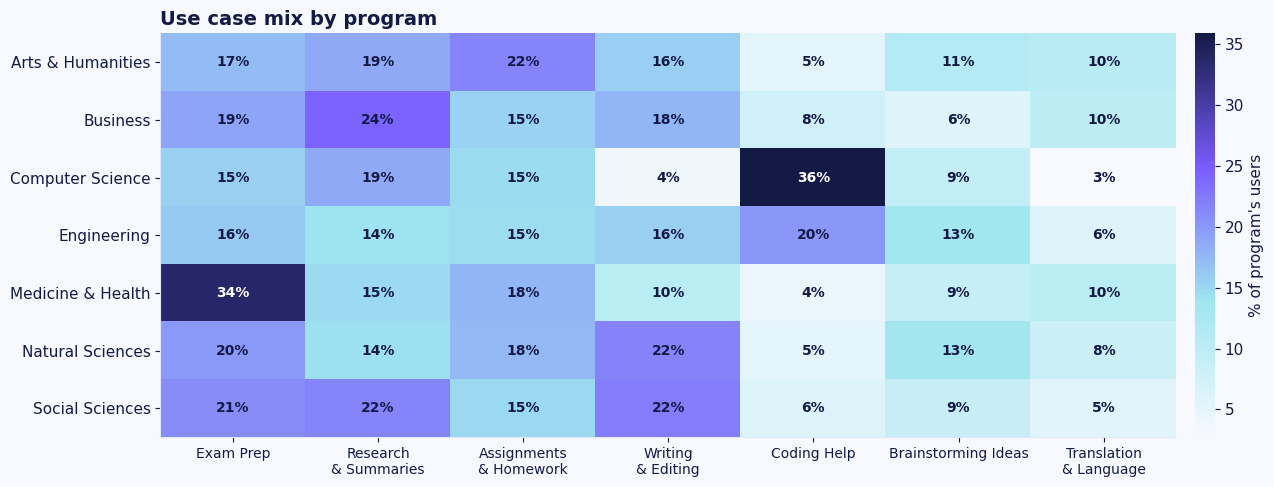

In [3]:
ct = pd.crosstab(users["program"], users["primary_use_case"], normalize="index") * 100
ct = ct[ct.mean().sort_values(ascending=False).index]
cmap = LinearSegmentedColormap.from_list("pulse", ["#f7f9ff", "#9fe6f0", VIOLET, INK])

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(ct.values, cmap=cmap, aspect="auto")
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels([c.replace(" & ", "\n& ") for c in ct.columns], fontsize=10)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index); ax.grid(False)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=10, fontweight="bold",
                color="white" if v > 26 else INK)
cb = plt.colorbar(im, ax=ax, pad=.015); cb.outline.set_visible(False); cb.set_label("% of program's users")
ax.set_title("Use case mix by program")
plt.tight_layout(); plt.show()

<div style="background:#effbfd;border-left:5px solid #17b8cf;border-radius:10px;padding:14px 18px;color:#141a46;font-size:15px;line-height:1.6;margin:6px 0 4px 0;font-family:'Segoe UI',Arial,sans-serif"><b style="color:#0a8aa0">&#128161; Insight:</b> Computer Science users lean on AI for <b>Coding Help</b> (36% of them) and Medicine &amp; Health users for <b>Exam Prep</b> (34%). Business students lean most on <b>Research &amp; Summaries</b> (24%).</div>

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">4</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">Is there a sweet spot for AI use?</div><div style="font-size:14px;color:#5b6498;margin-top:3px">CGPA and critical-thinking score by weekly AI hours (mean with 95% confidence band)</div></div></div>

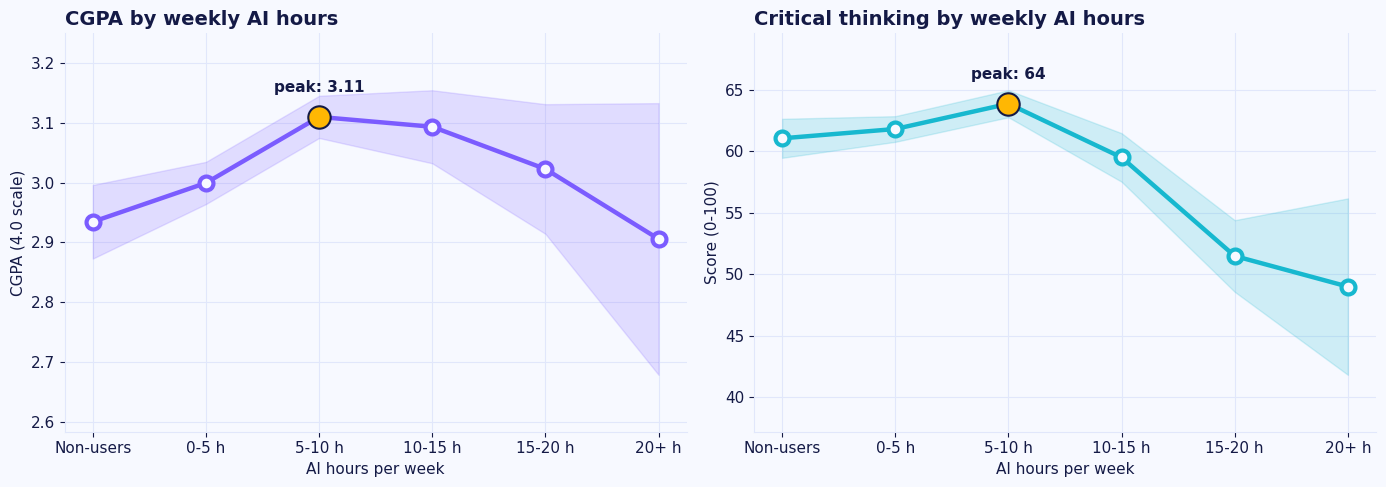

In [4]:
g = df.groupby("ai_hours_bin", observed=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, color, title, unit in [(axes[0], "cgpa", VIOLET, "CGPA by weekly AI hours", "CGPA (4.0 scale)"),
                                    (axes[1], "critical_thinking_score", CYAN, "Critical thinking by weekly AI hours", "Score (0-100)")]:
    m = g[col].mean(); ci = 1.96 * g[col].std() / np.sqrt(g[col].count())
    x = np.arange(len(m))
    ax.fill_between(x, m - ci, m + ci, color=color, alpha=.18)
    ax.plot(x, m, color=color, lw=3.2, marker="o", ms=10, mfc=BG, mew=3)
    pk = m.idxmax(); xi = list(m.index).index(pk)
    ax.scatter([xi], [m[pk]], s=260, color=GOLD, zorder=5, edgecolor=INK, linewidth=1.5)
    ax.annotate(f"peak: {m[pk]:.2f}" if col == "cgpa" else f"peak: {m[pk]:.0f}", (xi, m[pk]),
                textcoords="offset points", xytext=(0, 18), ha="center", fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(m.index); ax.set_ylabel(unit); ax.set_title(title)
    ax.set_xlabel("AI hours per week"); ax.margins(y=.2)
plt.tight_layout(); plt.show()

<div style="background:#effbfd;border-left:5px solid #17b8cf;border-radius:10px;padding:14px 18px;color:#141a46;font-size:15px;line-height:1.6;margin:6px 0 4px 0;font-family:'Segoe UI',Arial,sans-serif"><b style="color:#0a8aa0">&#128161; Insight:</b> Grades peak at <b>5-10 h</b> of AI per week (CGPA 3.11 vs 2.93 for non-users). Past that, CGPA slips back to 2.91, and critical thinking falls from 64 to 49 points for the heaviest users. This is a simulated pattern, so it shows a shape to practise with, not a real-world causal claim.</div>

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">5</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">When does AI use turn into dependency?</div><div style="font-size:14px;color:#5b6498;margin-top:3px">Dependency level by AI hours, and the time students say AI saves them</div></div></div>

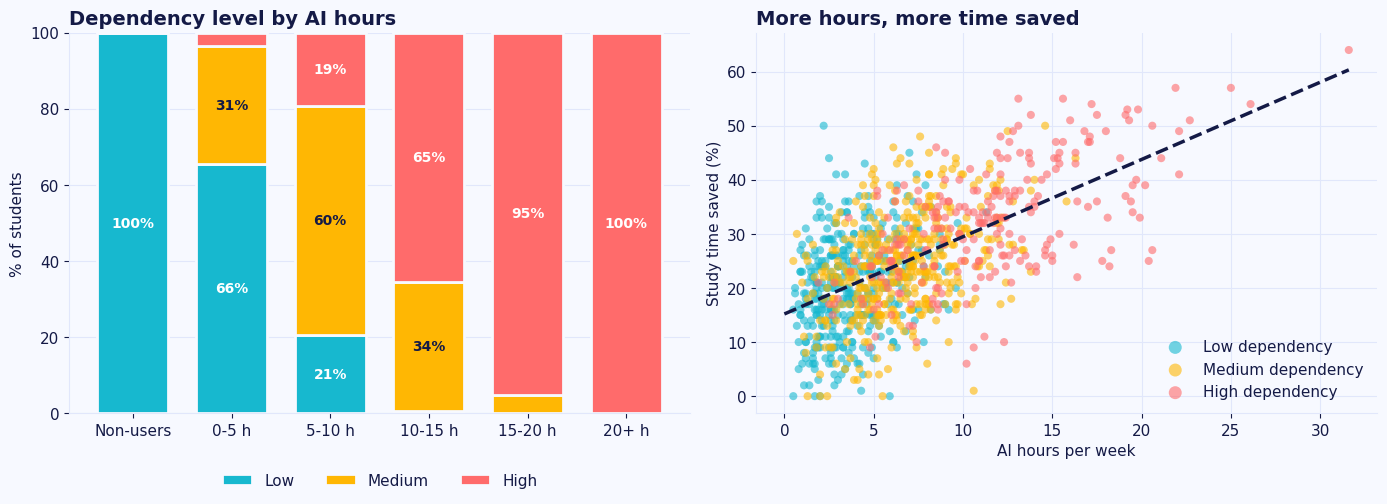

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.2))

share = pd.crosstab(df["ai_hours_bin"], df["ai_dependency_level"], normalize="index")[["Low", "Medium", "High"]] * 100
bottom = np.zeros(len(share))
for lvl, col in zip(["Low", "Medium", "High"], [CYAN, GOLD, CORAL]):
    a.bar(share.index, share[lvl], bottom=bottom, color=col, label=lvl, width=.72, edgecolor=BG, linewidth=2)
    for i, v in enumerate(share[lvl]):
        if v > 7: a.text(i, bottom[i] + v/2, f"{v:.0f}%", ha="center", va="center", fontweight="bold", color="white" if lvl != "Medium" else INK, fontsize=10)
    bottom += share[lvl].values
a.set_ylabel("% of students"); a.set_title("Dependency level by AI hours"); a.grid(axis="x", visible=False)
a.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.12))

lvl_col = {"Low": CYAN, "Medium": GOLD, "High": CORAL}
for lvl in ["Low", "Medium", "High"]:
    s = users[users["ai_dependency_level"] == lvl]
    b.scatter(s["ai_hours_per_week"], s["time_saved_pct"], s=34, alpha=.6, color=lvl_col[lvl], label=f"{lvl} dependency", edgecolor="none")
m_, c_ = np.polyfit(users["ai_hours_per_week"], users["time_saved_pct"], 1)
xs = np.linspace(0, users["ai_hours_per_week"].max(), 50); b.plot(xs, m_*xs + c_, color=INK, lw=2.5, ls="--")
b.set_xlabel("AI hours per week"); b.set_ylabel("Study time saved (%)"); b.set_title("More hours, more time saved")
b.legend(markerscale=1.6, loc="lower right")
plt.tight_layout(); plt.show()

<div style="background:#effbfd;border-left:5px solid #17b8cf;border-radius:10px;padding:14px 18px;color:#141a46;font-size:15px;line-height:1.6;margin:6px 0 4px 0;font-family:'Segoe UI',Arial,sans-serif"><b style="color:#0a8aa0">&#128161; Insight:</b> Only 4% of light users (0-5 h) reach <b>High</b> dependency, compared with 95% at 15-20 hours and 100% above 20. Paid subscribers save 32% of their study time vs 24% for free users.</div>

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">6</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">University policy, integrity &amp; AI detectors</div><div style="font-size:14px;color:#5b6498;margin-top:3px">Do bans work, and can detectors be trusted?</div></div></div>

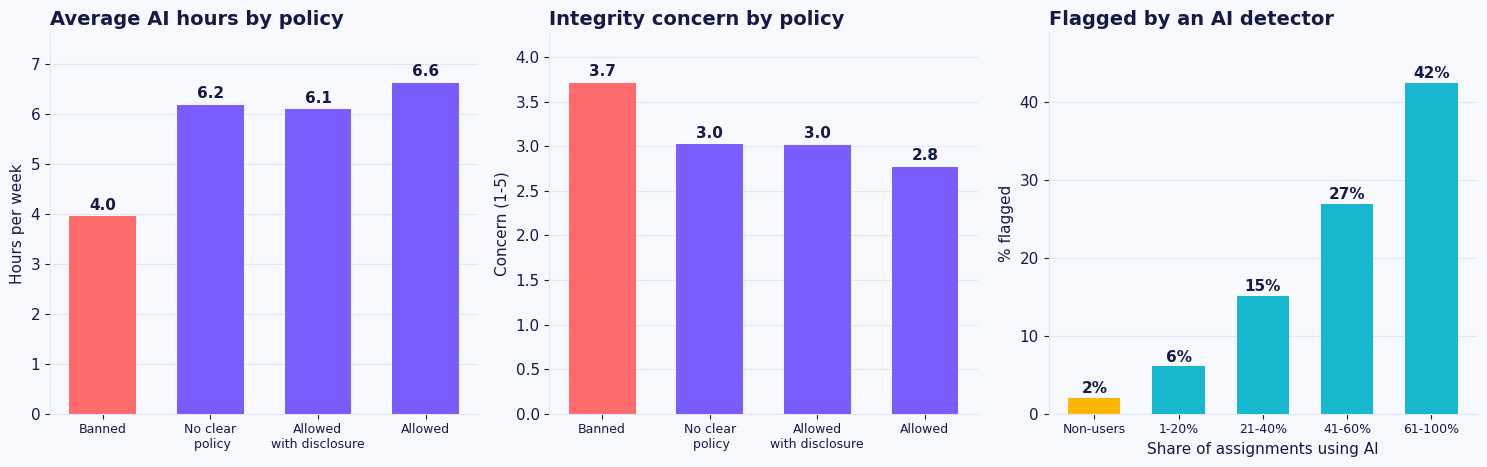

In [6]:
order = ["Banned", "No clear policy", "Allowed with disclosure", "Allowed"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

p = df.groupby("uni_ai_policy")[["ai_hours_per_week", "integrity_concern_level"]].mean().reindex(order)
for ax, col, title, lab in [(axes[0], "ai_hours_per_week", "Average AI hours by policy", "Hours per week"),
                            (axes[1], "integrity_concern_level", "Integrity concern by policy", "Concern (1-5)")]:
    cs = [CORAL if o == "Banned" else VIOLET for o in order]
    r = ax.bar([o.replace(" with ", "\nwith ").replace("No clear", "No clear\n") for o in order], p[col], color=cs, width=.62)
    for rect, v in zip(r, p[col]): ax.text(rect.get_x() + rect.get_width()/2, v + p[col].max()*.02, f"{v:.1f}", ha="center", fontweight="bold")
    ax.set_title(title); ax.set_ylabel(lab); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", labelsize=9)
    ax.set_ylim(0, p[col].max() * 1.15)

bins = pd.cut(df["ai_assignment_share_pct"], [-1, 0, 20, 40, 60, 100], labels=["Non-users", "1-20%", "21-40%", "41-60%", "61-100%"])
fl = (df["flagged_by_ai_detector"] == "Yes").groupby(bins, observed=True).mean() * 100
cs = [GOLD] + [CYAN] * 4
r = axes[2].bar(fl.index, fl.values, color=cs, width=.62)
for rect, v in zip(r, fl.values): axes[2].text(rect.get_x() + rect.get_width()/2, v + .6, f"{v:.0f}%", ha="center", fontweight="bold")
axes[2].set_title("Flagged by an AI detector"); axes[2].set_ylabel("% flagged"); axes[2].set_xlabel("Share of assignments using AI")
axes[2].grid(axis="x", visible=False); axes[2].tick_params(axis="x", labelsize=9); axes[2].set_ylim(0, fl.max() * 1.15)
plt.tight_layout(); plt.show()

<div style="background:#effbfd;border-left:5px solid #17b8cf;border-radius:10px;padding:14px 18px;color:#141a46;font-size:15px;line-height:1.6;margin:6px 0 4px 0;font-family:'Segoe UI',Arial,sans-serif"><b style="color:#0a8aa0">&#128161; Insight:</b> Students under a <b>ban</b> use AI 4.0 h a week vs 6.6 h where it is allowed, yet report the highest integrity concern (3.7/5). Detectors are shaky too: 2% of <i>non-users</i> were flagged, against 15% of users and 42% of students using AI for over 60% of assignments.</div>

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">7</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">How do the numbers relate?</div><div style="font-size:14px;color:#5b6498;margin-top:3px">Correlation of the main numeric columns</div></div></div>

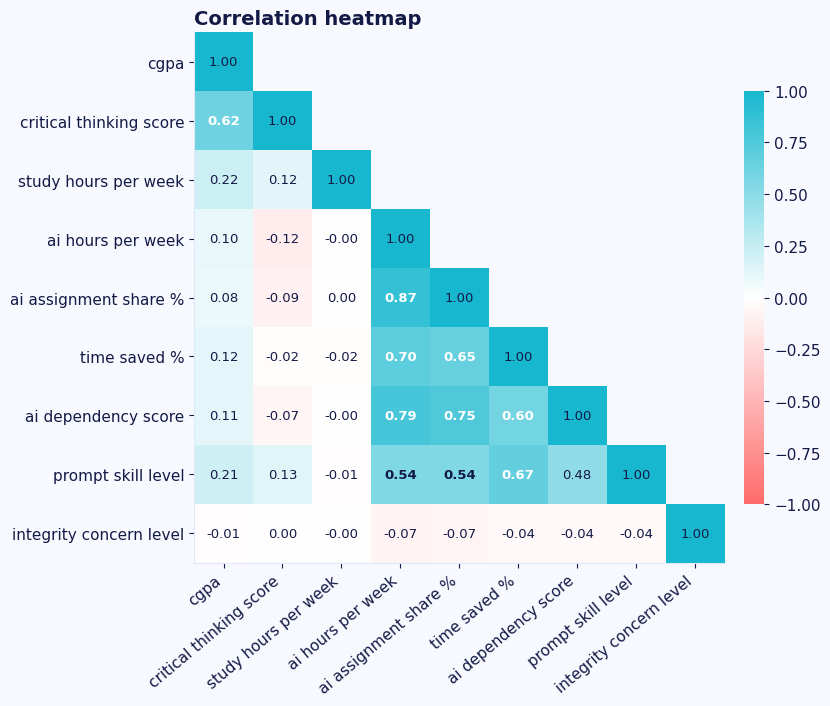

In [7]:
num = ["cgpa", "critical_thinking_score", "study_hours_per_week", "ai_hours_per_week", "ai_assignment_share_pct",
       "time_saved_pct", "ai_dependency_score", "prompt_skill_level", "integrity_concern_level"]
corr = df[num].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cm = LinearSegmentedColormap.from_list("div", [CORAL, "#ffffff", CYAN])
fig, ax = plt.subplots(figsize=(10.5, 7.2))
im = ax.imshow(np.ma.array(corr.values, mask=mask), cmap=cm, vmin=-1, vmax=1)
nice = [c.replace("_pct", " %").replace("_", " ") for c in num]
ax.set_xticks(range(len(num))); ax.set_xticklabels(nice, rotation=40, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(nice); ax.grid(False)
for i in range(len(num)):
    for j in range(i + 1):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9.5, fontweight="bold" if abs(v) > .5 and i != j else "normal",
                color="white" if abs(v) > .6 and i != j else INK)
cb = plt.colorbar(im, ax=ax, shrink=.78, pad=.02); cb.outline.set_visible(False)
ax.set_title("Correlation heatmap")
plt.tight_layout(); plt.show()

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">8</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">Can we predict grades and dependency?</div><div style="font-size:14px;color:#5b6498;margin-top:3px">Two quick baselines: Random Forest regression for CGPA, Random Forest classification for dependency level</div></div></div>

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, f1_score, confusion_matrix

numeric = ["age", "year_of_study", "ai_hours_per_week", "prompt_skill_level", "ai_assignment_share_pct",
           "study_hours_per_week", "critical_thinking_score", "time_saved_pct", "integrity_concern_level"]
categ = ["program", "university_type", "uni_ai_policy", "primary_use_case", "paid_ai_subscription"]
X = pd.get_dummies(df[numeric + categ], columns=categ, drop_first=True)

# --- 1) regression: CGPA ---
Xtr, Xte, ytr, yte = train_test_split(X, df["cgpa"], test_size=.2, random_state=42)
rfr = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42).fit(Xtr, ytr)
pred = rfr.predict(Xte); r2 = r2_score(yte, pred); mae = mean_absolute_error(yte, pred)

# --- 2) classification: dependency level (the score itself is excluded to avoid leakage) ---
order_lvl = ["Low", "Medium", "High"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X, df["ai_dependency_level"], test_size=.2, random_state=42, stratify=df["ai_dependency_level"])
rfc = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=42).fit(Xc_tr, yc_tr)
pc = rfc.predict(Xc_te); acc = accuracy_score(yc_te, pc); f1 = f1_score(yc_te, pc, average="macro")

print(f"CGPA regression       R2 = {r2:.2f} | average error = {mae:.2f} GPA points")
print(f"Dependency classifier accuracy = {acc:.2f} | macro F1 = {f1:.2f}")

CGPA regression       R2 = 0.41 | average error = 0.23 GPA points
Dependency classifier accuracy = 0.65 | macro F1 = 0.61


<div style="display:flex;gap:14px;flex-wrap:wrap;margin:10px 0"><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #7b5cff;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">CGPA model R&sup2;</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">0.41</div><div style="font-size:13px;color:#6a72a8">average error 0.23 GPA points</div></div><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #7b5cff;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">Dependency accuracy</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">65%</div><div style="font-size:13px;color:#6a72a8">Low / Medium / High</div></div><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #7b5cff;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">Macro F1</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">0.61</div><div style="font-size:13px;color:#6a72a8">balanced across the 3 classes</div></div><div style="flex:1;min-width:170px;background:#ffffff;border:1px solid #dbe2fb;border-top:5px solid #7b5cff;border-radius:14px;padding:16px 18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.4px;color:#6a72a8;text-transform:uppercase">Top CGPA driver</div><div style="font-size:30px;font-weight:bold;color:#141a46;margin:4px 0">Critical Thinking Score</div><div style="font-size:13px;color:#6a72a8">from Random Forest importances</div></div></div>

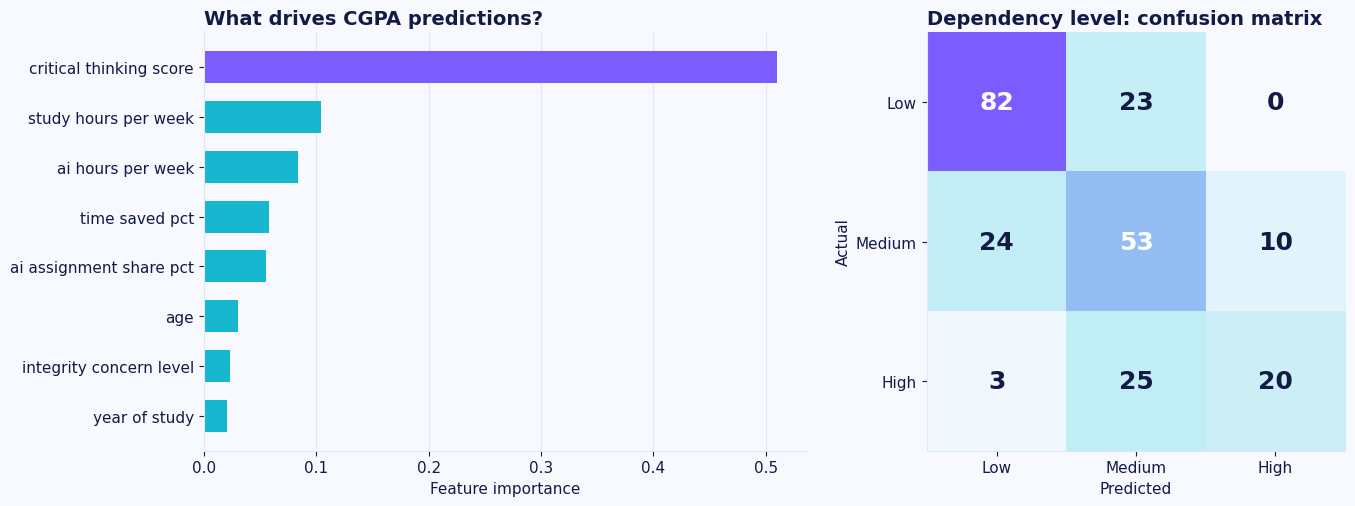

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})

imp = pd.Series(rfr.feature_importances_, index=X.columns).sort_values().tail(8)
names = [n.replace("_", " ").replace("program ", "program: ").replace("primary use case ", "use: ") for n in imp.index]
a.barh(names, imp.values, color=[VIOLET if v == imp.max() else CYAN for v in imp.values], height=.64)
a.set_title("What drives CGPA predictions?"); a.set_xlabel("Feature importance"); a.grid(axis="y", visible=False)

cmx = confusion_matrix(yc_te, pc, labels=order_lvl)
cmap2 = LinearSegmentedColormap.from_list("cm", ["#f7f9ff", "#9fe6f0", VIOLET])
b.imshow(cmx, cmap=cmap2); b.grid(False)
b.set_xticks(range(3)); b.set_xticklabels(order_lvl); b.set_yticks(range(3)); b.set_yticklabels(order_lvl)
for i in range(3):
    for j in range(3):
        b.text(j, i, cmx[i, j], ha="center", va="center", fontsize=18, fontweight="bold", color="white" if cmx[i, j] > cmx.max()*.55 else INK)
b.set_xlabel("Predicted"); b.set_ylabel("Actual"); b.set_title("Dependency level: confusion matrix")
plt.tight_layout(); plt.show()

<div style="display:flex;align-items:center;gap:16px;margin:30px 0 8px 0;padding:16px 20px;background:#eef2ff;border-radius:14px;border-left:6px solid #7b5cff;font-family:'Segoe UI',Arial,sans-serif"><div style="min-width:46px;height:46px;border-radius:12px;background:linear-gradient(135deg,#17b8cf,#7b5cff);color:#fff;font-weight:bold;font-size:21px;display:flex;align-items:center;justify-content:center">9</div><div><div style="font-size:24px;font-weight:bold;color:#141a46;line-height:1.2">Key takeaways</div><div style="font-size:14px;color:#5b6498;margin-top:3px">What the data says in five lines</div></div></div>

<div style="display:flex;gap:14px;flex-wrap:wrap"><div style="flex:1;min-width:210px;background:linear-gradient(160deg,#ffffff,#eef2ff);border:1px solid #dbe2fb;border-radius:16px;padding:18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:30px">&#127919;</div><div style="font-weight:bold;font-size:16px;color:#141a46;margin:6px 0">A sweet spot exists</div><div style="font-size:13.5px;color:#5b6498;line-height:1.5">Best grades at 5-10 h a week; very heavy use goes with lower grades and weaker critical thinking.</div></div><div style="flex:1;min-width:210px;background:linear-gradient(160deg,#ffffff,#eef2ff);border:1px solid #dbe2fb;border-radius:16px;padding:18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:30px">&#9888;&#65039;</div><div style="font-weight:bold;font-size:16px;color:#141a46;margin:6px 0">Dependency builds fast</div><div style="font-size:13.5px;color:#5b6498;line-height:1.5">100% of students above 20 h a week are in the High dependency group.</div></div><div style="flex:1;min-width:210px;background:linear-gradient(160deg,#ffffff,#eef2ff);border:1px solid #dbe2fb;border-radius:16px;padding:18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:30px">&#128187;</div><div style="font-weight:bold;font-size:16px;color:#141a46;margin:6px 0">Fields differ</div><div style="font-size:13.5px;color:#5b6498;line-height:1.5">Computer Science uses AI the most and mostly for coding help; Medicine & Health the least.</div></div><div style="flex:1;min-width:210px;background:linear-gradient(160deg,#ffffff,#eef2ff);border:1px solid #dbe2fb;border-radius:16px;padding:18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:30px">&#128737;&#65039;</div><div style="font-weight:bold;font-size:16px;color:#141a46;margin:6px 0">Policies and detectors are imperfect</div><div style="font-size:13.5px;color:#5b6498;line-height:1.5">Bans cut hours but raise integrity concerns, and 2% of non-users still got flagged.</div></div><div style="flex:1;min-width:210px;background:linear-gradient(160deg,#ffffff,#eef2ff);border:1px solid #dbe2fb;border-radius:16px;padding:18px;font-family:'Segoe UI',Arial,sans-serif"><div style="font-size:30px">&#129302;</div><div style="font-weight:bold;font-size:16px;color:#141a46;margin:6px 0">A good baseline to beat</div><div style="font-size:13.5px;color:#5b6498;line-height:1.5">Simple Random Forests reach R&sup2; 0.41 for CGPA and 65% accuracy for dependency level. Can you do better?</div></div></div><div style="margin-top:20px;padding:20px 24px;background:linear-gradient(135deg,#080c2b,#2b2a8f);color:#f4f7ff;border-radius:16px;font-size:14.5px;line-height:1.7;font-family:'Segoe UI',Arial,sans-serif"><b style="color:#48d6e6">Try next:</b> add a country-level comparison &middot; test whether paid plans change grades &middot; build a classifier for <code style="color:#48d6e6;background:transparent">flagged_by_ai_detector</code> &middot; cluster students into usage personas.<br><span style="color:#b9c2ee">If this notebook helped you, an upvote on the notebook and the dataset means a lot! &#127891;</span></div>